X_train shape: (7980, 24, 3)
y_train shape: (7980,)
X_test shape: (1996, 24, 3)
y_test shape: (1996,)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 24, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,369 (118.63 KB)

 Trainable params: 30,369 (118.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - loss: 0.0359 - mae: 0.1347 - val_loss: 0.0056 - val_mae: 0.0589
Epoch 2/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0091 - mae: 0.0739 - val_loss: 0.0053 - val_mae: 0.0574
Epoch 3/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - loss: 0.0077 - mae: 0.0690 - val_loss: 0.0055 - val_mae: 0.0589
Epoch 4/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0072 - mae: 0.0664 - val_loss: 0.0054 - val_mae: 0.0582
Epoch 5/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0068 - mae: 0.0644 - val_loss: 0.0062 - val_mae: 0.0627
Epoch 6/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - loss: 0.0066 - mae: 0.0635 - val_loss: 0.0061 - val_mae: 0.0617
Epoch 7/30
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - loss: 0.0062 - mae: 0.0620 - val_loss: 0.0057 - val_mae: 0.0594
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

--- Model Performance Metrics ---
Mean Absolute Error (MAE): 0.0546
Root Mean Squared Error (RMSE): 0.0694


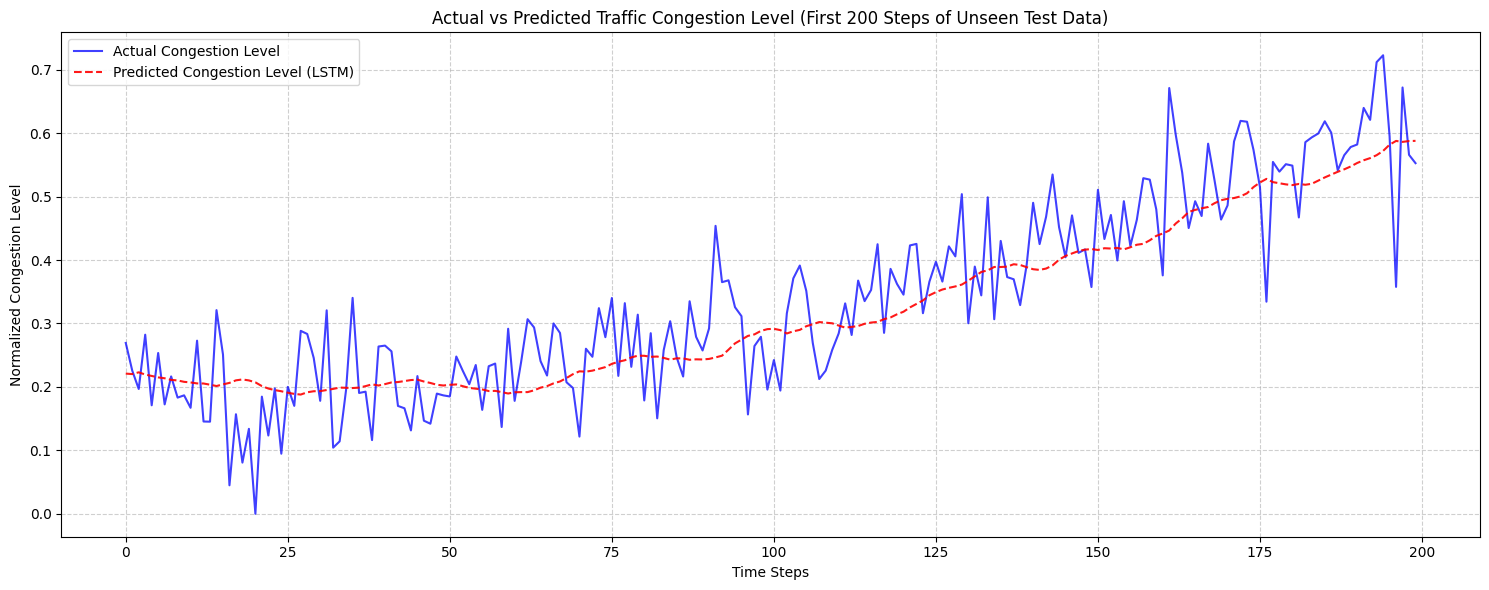

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Align shape details from existing variables
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# 2. Build the LSTM model
model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, activation='relu', return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)  # Predict single continuous value (congestion level)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

# 3. Train the model
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)

# 4. Predict on the unseen test data
y_pred = model.predict(X_test).flatten()

# 5. Evaluate the model performance using MAE and RMSE
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

# 6. Plot actual vs predicted congestion values for a subset of unseen data
plt.figure(figsize=(15, 6))
plt.plot(y_test[:200], label='Actual Congestion Level', color='blue', alpha=0.75)
plt.plot(y_pred[:200], label='Predicted Congestion Level (LSTM)', color='red', linestyle='--', alpha=0.9)
plt.title('Actual vs Predicted Traffic Congestion Level (First 200 Steps of Unseen Test Data)')
plt.xlabel('Time Steps')
plt.ylabel('Normalized Congestion Level')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()